# Murphy: LATTE in buffered ADCP crossing windows

Each crossing uses its `transects.json` UTC interval plus the before/after hours in `murphy_latte_buffered.json`. All ADCP samples inside that expanded interval are fitted, including off-line ship-track positions. Each crossing starts from its own shallowest accepted SOLO inner centre. The across-crossing figures come first; the selected crossing's diagnostics and reconstructions are at the bottom. Fits at different times are compared, not averaged.


In [1]:
from pathlib import Path
import importlib.util
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.patches import Rectangle

candidates = [Path.cwd(), *Path.cwd().parents,
              Path.cwd() / "seacofs_eddy_tilt_analysis" / "observations"]
OBSERVATIONS_DIR = next(p for p in candidates
                        if p.name == "observations" and (p / "esp_depth_tools.py").is_file())
spec = importlib.util.spec_from_file_location("esp_depth_tools", OBSERVATIONS_DIR / "esp_depth_tools.py")
esp = importlib.util.module_from_spec(spec)
spec.loader.exec_module(esp)

In [ ]:
EDDY = "Murphy"
STUDY_DIR = OBSERVATIONS_DIR / "MNF_IN2015_V03_adcp_trawler"
CONFIG_PATH = STUDY_DIR / "murphy_latte_buffered.json"
CONFIG = json.loads(CONFIG_PATH.read_text())
TRANSECTS_PATH = STUDY_DIR / CONFIG["transects_config"]
BACKEND_PATH = Path(CONFIG["backend_path"])
DATA_PATH, transects, _ = esp.load_study(TRANSECTS_PATH, EDDY, load_adcp=False)
ALL_TRANSECT_IDS = set(transects.index)
OUTPUT_DIR = DATA_PATH.parent / "outputs"
SOLO_RESULTS_PATH = OUTPUT_DIR / "murphy_solo_depth_fits.csv"
solo = pd.read_csv(SOLO_RESULTS_PATH)
backend, backend_info = esp.load_backend(BACKEND_PATH)
MIN_ATTENDANCE = CONFIG["min_attendance"]
BUFFER_FIT = CONFIG["fit"]
HALF_WIDTH_KM = CONFIG["half_width_km"]
VELOCITY_LIMIT = CONFIG["velocity_limit"]
unknown_config_ids = (set(CONFIG["buffer_hours"]) | set(CONFIG["fit_overrides"])) - ALL_TRANSECT_IDS
if unknown_config_ids:
    raise ValueError(f"Unknown crossing IDs in buffered config: {sorted(unknown_config_ids)}")
BUFFER_OVERRIDES = {k: tuple(v) for k, v in CONFIG["buffer_hours"].items() if k in transects.index}
FIT_OVERRIDES = {k: v for k, v in CONFIG["fit_overrides"].items() if k in transects.index}
if set(transects.index) - set(BUFFER_OVERRIDES):
    raise ValueError(f"Missing buffer hours for {sorted(set(transects.index) - set(BUFFER_OVERRIDES))}")
display(transects)


## Fit buffered crossings

Change crossing windows in `transects.json` and per-crossing buffer hours in `murphy_latte_buffered.json`. Rerun `murphy_solo.ipynb` and its export after editing the crossings or SOLO settings. All selected crossing windows are fitted independently with the shared LATTE settings in this notebook's config.


In [10]:
buffered_runs, buffered_summary, buffered_results = esp.fit_buffered_latte_transects(
    DATA_PATH, transects, solo, backend, BUFFER_FIT,
    buffer_overrides=BUFFER_OVERRIDES, min_attendance=MIN_ATTENDANCE,
    fit_overrides=FIT_OVERRIDES)
display(buffered_summary)


## Compare every buffered crossing

Centre offsets are measured from each crossing's own shallowest accepted centre. `Rc` and Gaussian vector R² show accepted outer fits; axis ratio, orientation, and inner vorticity show accepted inner fits. Gaps mark rejected levels. Freddy visit 2 is dashed; its later date and OS150 depth grid should be interpreted separately.


In [ ]:
fig = esp.plot_buffered_latte_comparison(buffered_runs, EDDY)
plt.show()


## Export buffered-transect LATTE results

These files are separate from the full regional LATTE export. They retain every depth and crossing, actual selected times, per-crossing buffers, SOLO seed depth and fit settings.


In [14]:
SAVE_BUFFERED_RESULTS = CONFIG["save_results"]
if SAVE_BUFFERED_RESULTS:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    buffered_results.to_csv(OUTPUT_DIR / "murphy_latte_buffered_depth_fits.csv", index=False)
    buffered_provenance = dict(eddy=EDDY, method="LATTE", selection="SOLO crossings plus time buffers",
                               data_path=str(DATA_PATH), config_path=str(CONFIG_PATH), transects_config_path=str(TRANSECTS_PATH),
                               solo_results_path=str(SOLO_RESULTS_PATH), backend=backend_info,
                               buffer_overrides=BUFFER_OVERRIDES, fit_settings=BUFFER_FIT, fit_overrides=FIT_OVERRIDES,
                               transects=transects.reset_index().to_dict(orient="records"),
                               crossings={ident: run["audit"] for ident, run in buffered_runs.items()})
    (OUTPUT_DIR / "murphy_latte_buffered_provenance.json").write_text(
        json.dumps(buffered_provenance, indent=2, default=str))
    print(f"Saved buffered LATTE results to {OUTPUT_DIR}")


Saved buffered LATTE results to /srv/scratch/z5297792/tilt_observation_data/MNF_IN2015_V03_adcp_trawler/outputs


## Selected buffered crossing: diagnostics and depth structure

Change `active_transect` in this notebook's JSON config, then rerun this cell and those below; the fitted runs need not be repeated. The following figures show only that crossing. Magenta and green dots in horizontal maps identify inner and additional outer-fit ADCP samples; failed levels remain in the diagnostics.


selected_rows                                              13467
used_rows                                                  13467
unique_times                                                 276
start_utc                              2015-06-04 15:01:21+00:00
end_utc                                2015-06-05 13:56:21+00:00
depth_range_m                                      [30.4, 814.4]
missing_avg_qc                                             13467
zero_attendance_rows                                        6843
min_attendance                                              None
origin_lon_lat          (154.85018371042003, -28.61156558451823)
bounds_lon_lat                                              None
window_start_utc                       2015-06-04 15:00:00+00:00
window_end_utc                         2015-06-05 14:00:00+00:00
buffer_before_hours                                          7.0
buffer_after_hours                                           7.0
solo_seed_depth_m        

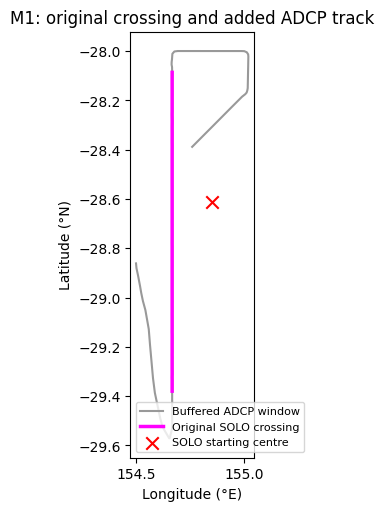

LATTE: 37/50 accepted inner fits; 37/50 accepted Gaussian reconstructions.
status
insufficient_core    11
invalid_ellipse       2
ok                   37
Centre offsets reference the shallowest accepted fit: 62.4 m.
Reconstructed measured levels: 62.4–638.4 m (gaps retained).
The ADCP sampling limit is not an estimate of the eddy bottom. R² is in-sample.


,depth_m,status,n_obs,n_core,inner_valid,valid,xc_lon,yc_lat,Rc_m,vector_R2
0,30.4,invalid_ellipse,276,45,False,False,NaN,NaN,NaN,NaN
1,46.4,invalid_ellipse,276,45,False,False,NaN,NaN,NaN,NaN
2,62.4,ok,276,71,True,True,154.9224,-28.7024,122863.7877,0.7365
3,78.4,ok,276,113,True,True,154.7808,-28.6934,144003.2527,0.8069
4,94.4,ok,276,124,True,True,154.7615,-28.7040,172281.2305,0.8307
5,110.4,ok,276,129,True,True,154.7403,-28.7048,211096.8082,0.8392
6,126.4,ok,276,134,True,True,154.7282,-28.7071,201250.4675,0.8352
7,142.4,ok,276,130,True,True,154.7446,-28.7001,164423.1217,0.8195
8,158.4,ok,276,123,True,True,154.7624,-28.6990,160867.6254,0.8050
9,174.4,ok,276,110,True,True,154.8001,-28.6908,141697.7207,0.7943


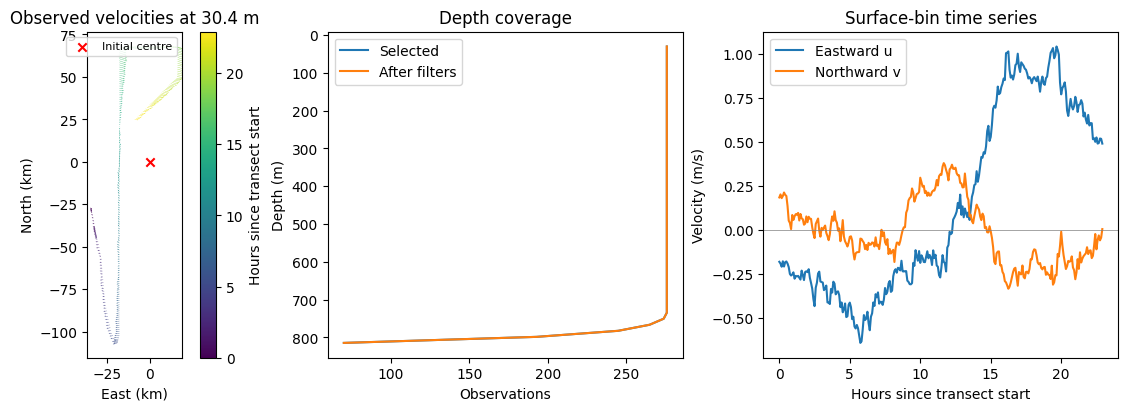

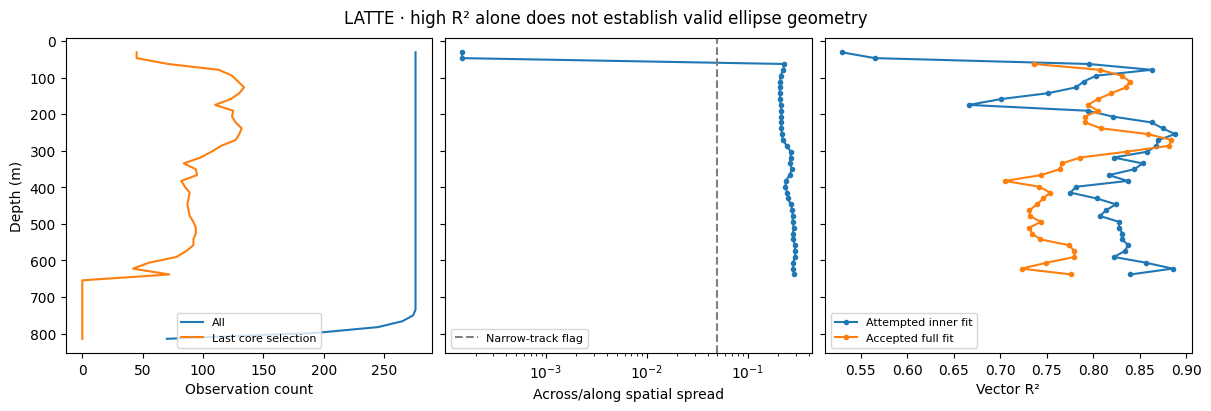

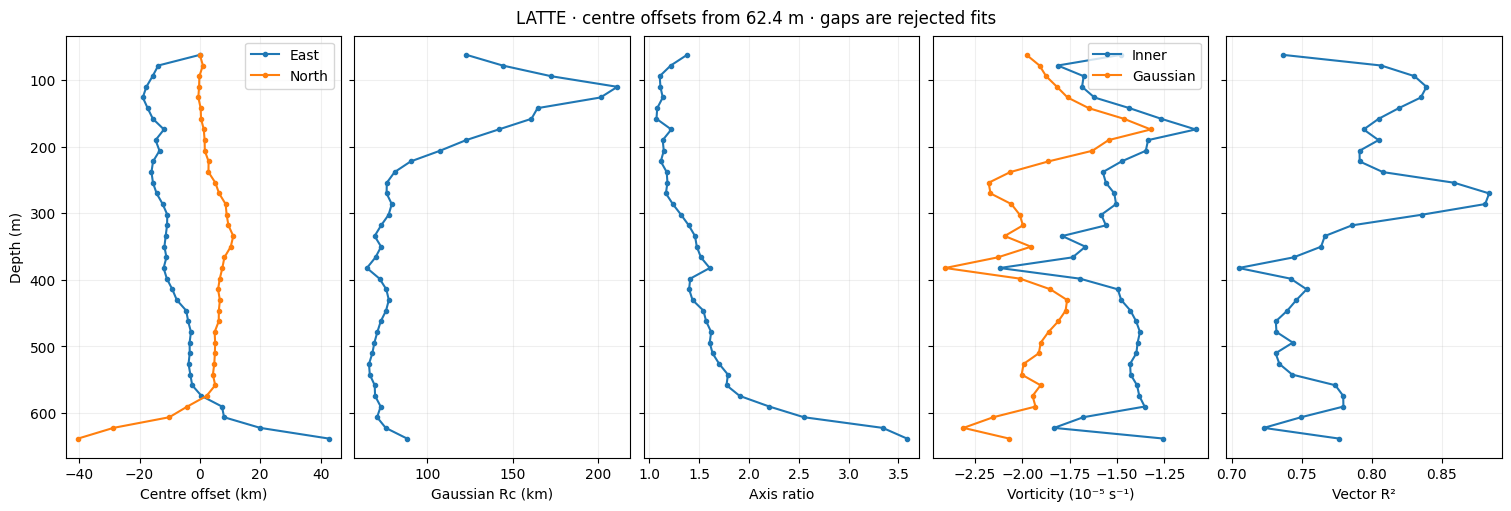

In [11]:
ACTIVE_BUFFERED_TRANSECT = json.loads(CONFIG_PATH.read_text())["active_transect"]
if ACTIVE_BUFFERED_TRANSECT not in buffered_runs:
    raise ValueError(f"Choose one of {list(buffered_runs)}")
buffered_run = buffered_runs[ACTIVE_BUFFERED_TRANSECT]
buffered_data = buffered_run["data"]
buffered_coverage = buffered_run["coverage"]
buffered_result = buffered_run["results"]
buffered_samples = buffered_run["samples"]
display(pd.Series(buffered_run["audit"], name=ACTIVE_BUFFERED_TRANSECT))
esp.plot_buffered_track(
    buffered_data, transects.loc[ACTIVE_BUFFERED_TRANSECT],
    buffered_run["solo_seed"], ACTIVE_BUFFERED_TRANSECT)
plt.show()
esp.report(buffered_result)
display(buffered_result[["depth_m", "status", "n_obs", "n_core", "inner_valid", "valid",
                         "xc_lon", "yc_lat", "Rc_m", "vector_R2"]].round(4))
esp.plot_sampling(buffered_data, buffered_coverage)
plt.show()
esp.plot_diagnostics(buffered_result)
plt.show()
esp.plot_profiles(buffered_result)
plt.show()


## Satellite surface velocity and buffered LATTE samples at the configured ADCP depth

OceanCurrent surface geostrophic velocity is interpolated to the middle observed ADCP timestamp of `ACTIVE_BUFFERED_TRANSECT`. The ADCP depth is set by `satellite_depth_m` in this notebook's config (200 m by default). Magenta points entered the LATTE inner fit; green points are additional samples used in the outer fit. Black shows the buffered ship track. Daily satellite maps are cached beside the ADCP CSV.

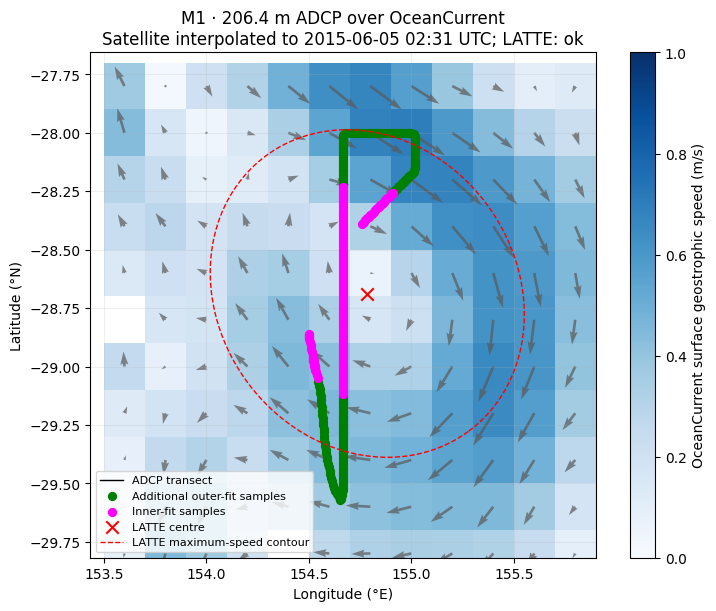

In [ ]:
fig, ax = esp.plot_solo_satellite_overlay(
    buffered_data, buffered_result, buffered_samples, DATA_PATH.parent,
    ACTIVE_BUFFERED_TRANSECT, half_width_km=CONFIG['satellite_half_width_km'],
    speed_max=VELOCITY_LIMIT, target_depth=CONFIG['satellite_depth_m'])
plt.show()

## Selected buffered crossing: reconstructed flow

Horizontal maps show nearest measured depths, including rejected levels. The 3-D and fixed zonal/meridional sections use the same conventions as the regional LATTE figures above.


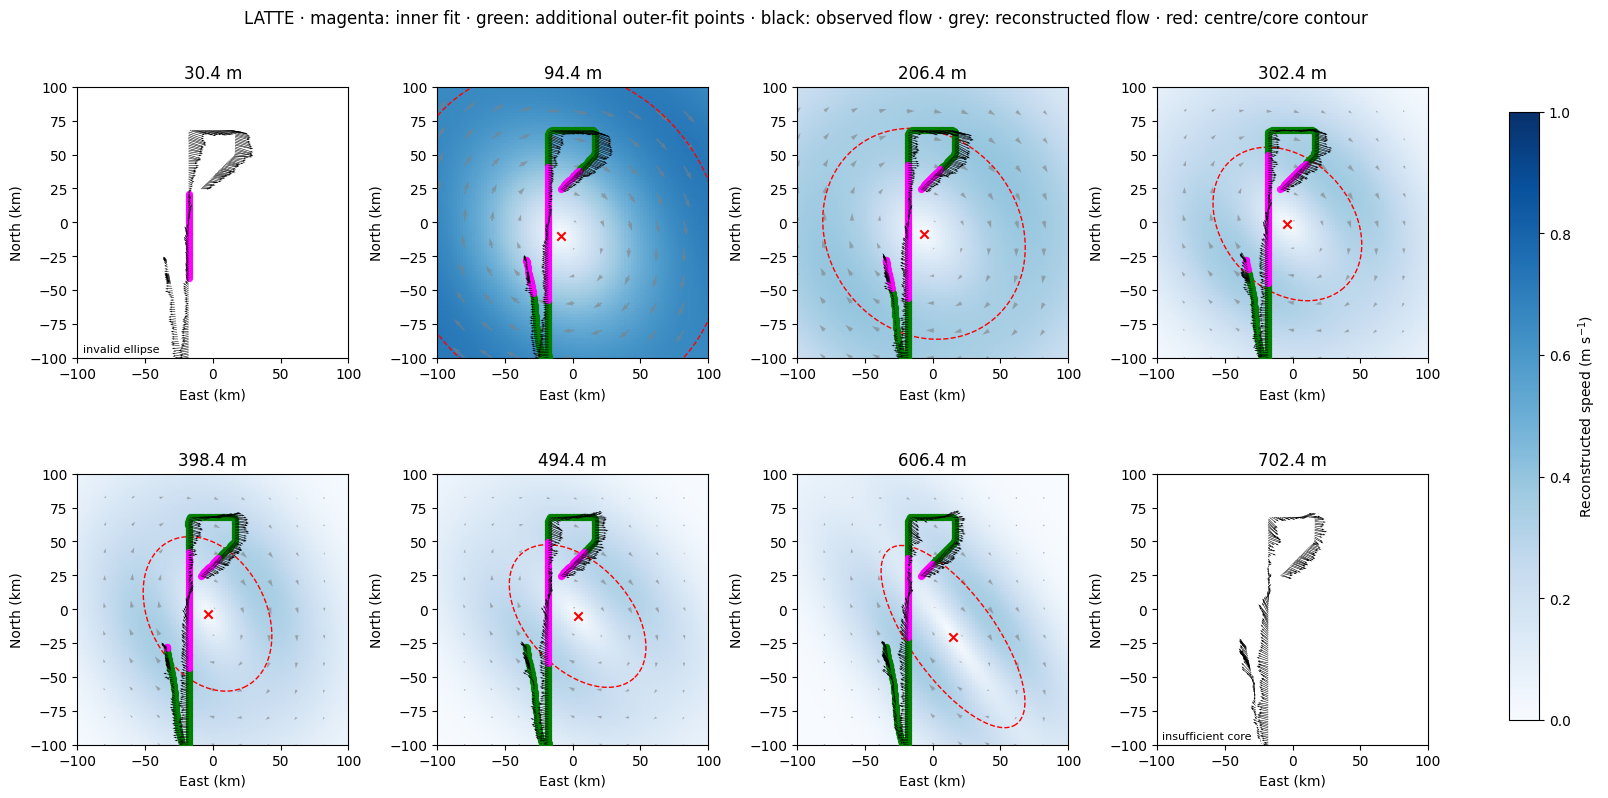

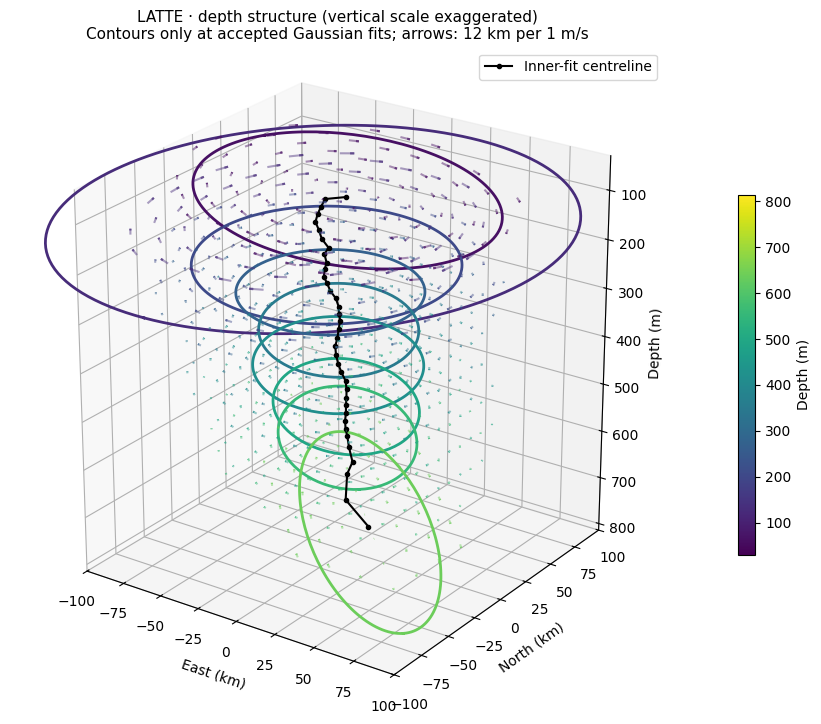

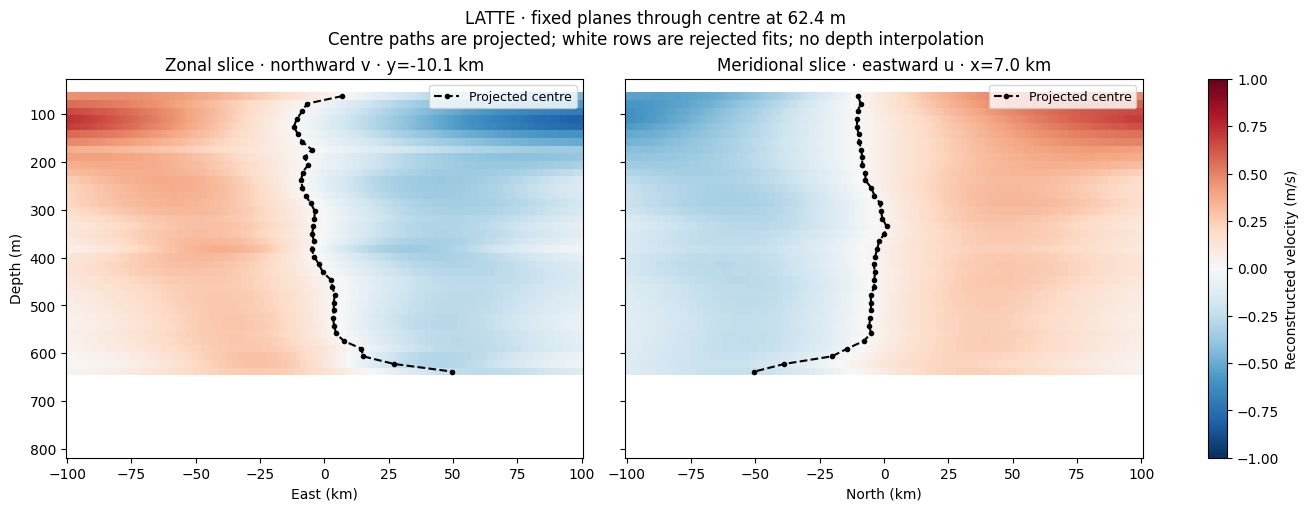

In [13]:
BUFFER_MAP_DEPTHS = tuple(CONFIG["map_depths"])
esp.plot_maps(buffered_result, buffered_samples, backend, depths=BUFFER_MAP_DEPTHS,
              half_width_km=HALF_WIDTH_KM, speed_max=VELOCITY_LIMIT)
plt.show()
esp.plot_3d(buffered_result, backend, half_width_km=HALF_WIDTH_KM)
plt.show()
esp.plot_sections(buffered_result, backend, half_width_km=HALF_WIDTH_KM,
                  speed_max=VELOCITY_LIMIT)
plt.show()
